# Checks of the fit with the systematic uncertainties

Three checks that the ABCD shape fit of `03_limits.ipynb` behaves with the systematics in,
for one signal point per final state, on the cards with corrections and systematics:

5. **Signal injection.** Toy datasets generated with the signal at a known strength, the
   point's expected limit and three times it, and fitted back
   (`sidm/scripts/run_combine_toys.py`). The pull of $r$ (its fitted minus its injected
   value, over its uncertainty) follows a unit Gaussian if the fit is unbiased and its
   uncertainty right, and every nuisance that the data do not constrain comes back as
   $0 \pm 1$.
6. **Likelihood scans.** $-2\Delta\ln L$ against $r$, with every nuisance and with
   statistics only, on the Asimov dataset without signal and with the signal at the
   expected limit, and against each systematic, with $r$ floating
   (`sidm/scripts/run_combine_scan.py`).
7. **Correlations.** The correlation matrix of every parameter of the signal-plus-background
   fit to the Asimov dataset with the signal at the expected limit
   (`sidm/scripts/run_combine_pulls.py`), the free background parameters included.

**Rerun after `03_limits.ipynb`** whenever an entry is added to `systematics.yaml`. Like
`04_systematic_effects.ipynb`, it reads the outputs of 03_limits from EOS and stops if they
are not from the current `systematics.yaml`.

**Simulation only.** The toys are generated from the model, and the cards' data_obs is never
fitted. The figures and fit outputs go to EOS, under `fit_checks/` in the output directory of
03_limits.

**Interpretations.** Each section ends with an interpretation of its results and of what they
mean for the analysis, written for the run named in it. Revise them when a rerun changes the
picture, for example after adding a systematic.

In [1]:
import json, os, shutil, sys, tempfile, warnings
from pathlib import Path
import fsspec
import numpy as np
from IPython.display import Image, display

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # sidm/studies/limit_plotting, put on the path by systematics_study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
dt = sysstudy.dt

CAMPAIGN = "systematics_v1"
dt.use_campaign(CAMPAIGN)
INPUT_DIR = sysstudy.eos_url(dt.CAMPAIGN.bkg_dir)   # the merged outputs of the campaign
LIMITS_DIR = f"{INPUT_DIR}_limits"                  # the outputs of 03_limits.ipynb
OUTPUT_DIR = f"{LIMITS_DIR}/fit_checks"
REGISTRY = sysstudy.load_registry()
KAPPAS = sysstudy.limits_outputs(LIMITS_DIR, REGISTRY)["kappas"]   # stops if 03_limits needs a rerun
LIMIT = set(sysstudy.limit_grid(study.signal_points())) & set(KAPPAS)
EXPECTED = {r["signal"]: r["exp"] for r in pt.as_rows(f"{LIMITS_DIR}/limits_with/limits.csv")}
POINTS = {"SR_2mu2e": "2Mu2E_500GeV_1p2GeV_1p9mm", "SR_4mu": "4Mu_500GeV_1p2GeV_1p9mm"}
NTOYS = 500   # per point and injected strength
COMBINE = sysstudy.find_combine()
WORK = Path(tempfile.mkdtemp(prefix=f"fit_checks_{CAMPAIGN}_"))   # removed at the end
FIGURES = WORK / "figures"


def show(path):
    """Display a figure that plot_tools saved"""
    display(Image(filename=str(path.with_suffix(".png"))))


print("inputs: ", INPUT_DIR, "and", LIMITS_DIR)
print("outputs:", OUTPUT_DIR)
print("Combine:", "on the PATH" if COMBINE and COMBINE.no_cmsenv else COMBINE.combine_cmssw if COMBINE else "not found")
print("systematics:", ", ".join(REGISTRY), f"| {len(LIMIT)} points on the limit grid")
print("points:", ", ".join(f"{p} (expected limit {EXPECTED[p]:.3g} fb)" for p in POINTS.values()))

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v1 and root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v1_limits
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v1_limits/fit_checks
Combine: /uscms_data/d3/scampbel/CMSSW_14_1_0_pre4
systematics: lumi_13TeV, CMS_pileup, CMS_l1_prefiring, CMS_jet_energy | 96 points on the limit grid
points: 2Mu2E_500GeV_1p2GeV_1p9mm (expected limit 1.56 fb), 4Mu_500GeV_1p2GeV_1p9mm (expected limit 0.152 fb)


## 5. Signal injection

Left, the fitted $r$ of the toys against the injected value, with their mean; middle, its
pull against a unit Gaussian, with the median and the half-width of the central 68% of the
pulls (the mean and width of a Gaussian, but not thrown off by a few toys with a broken
uncertainty); right, the mean and spread of every fitted
nuisance over the toys against $0 \pm 1$. The limits keep $r \geq 0$, so a toy whose best fit
would lie below zero stops there: at the expected limit, which is about two standard
deviations above zero, some toys gather at $r = 0$ and in the left tail of the pull. At three
times the expected limit that should no longer happen. Fits that fail (status not 0) are
left out and counted in the title.

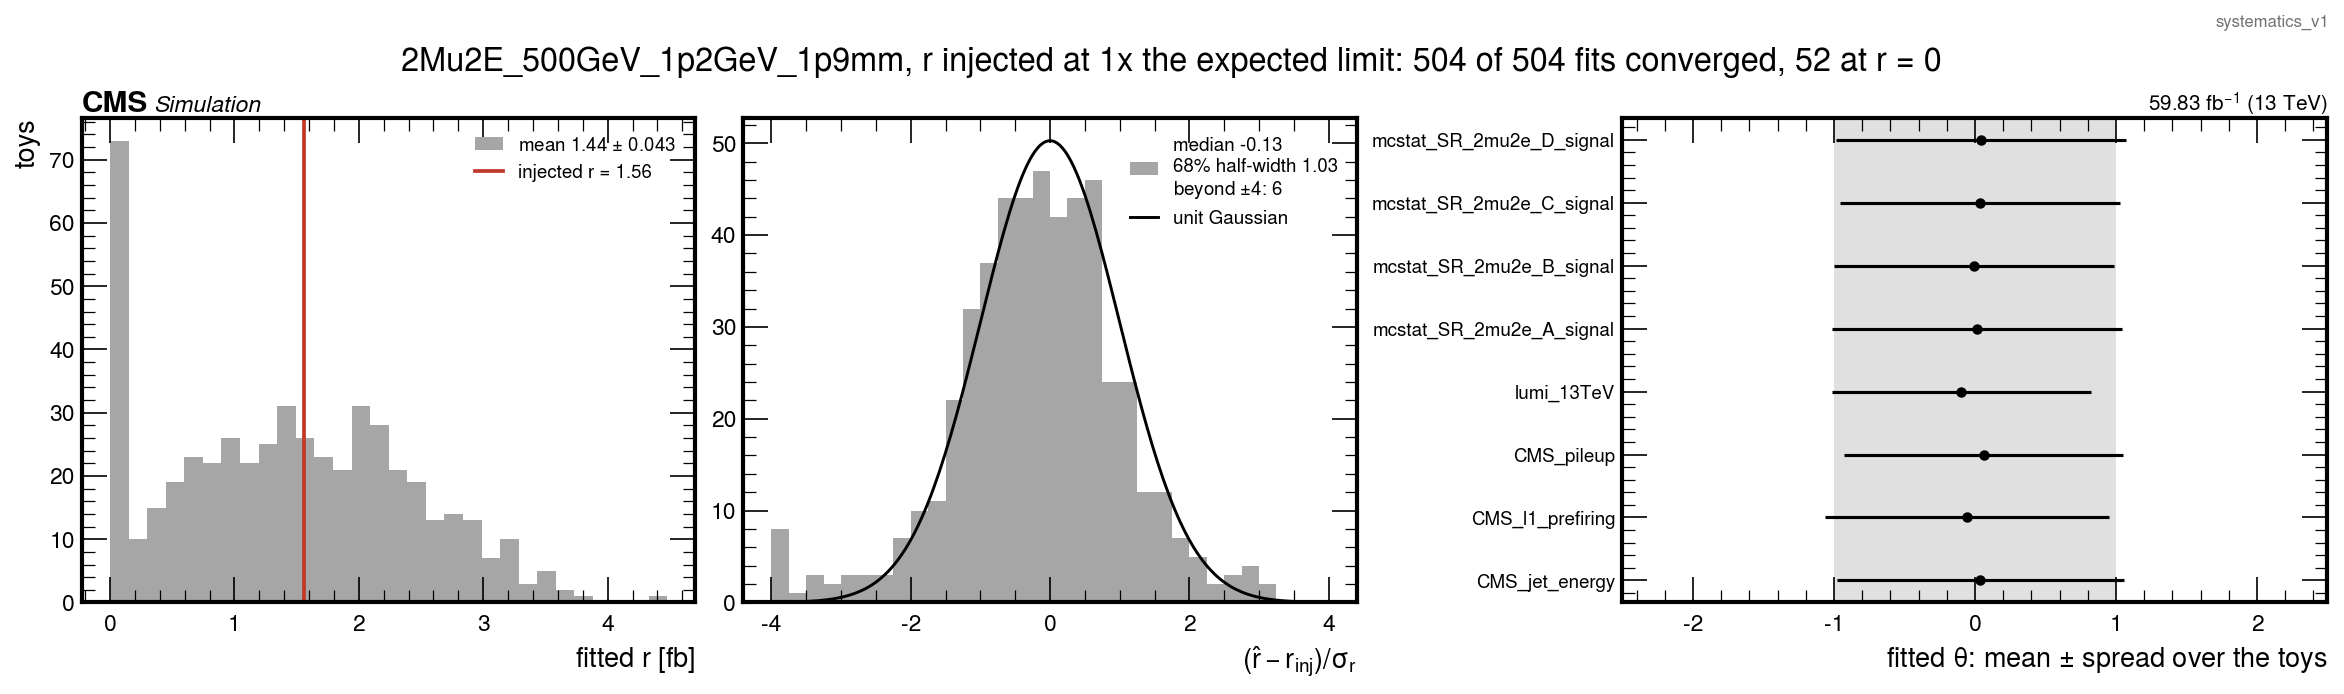

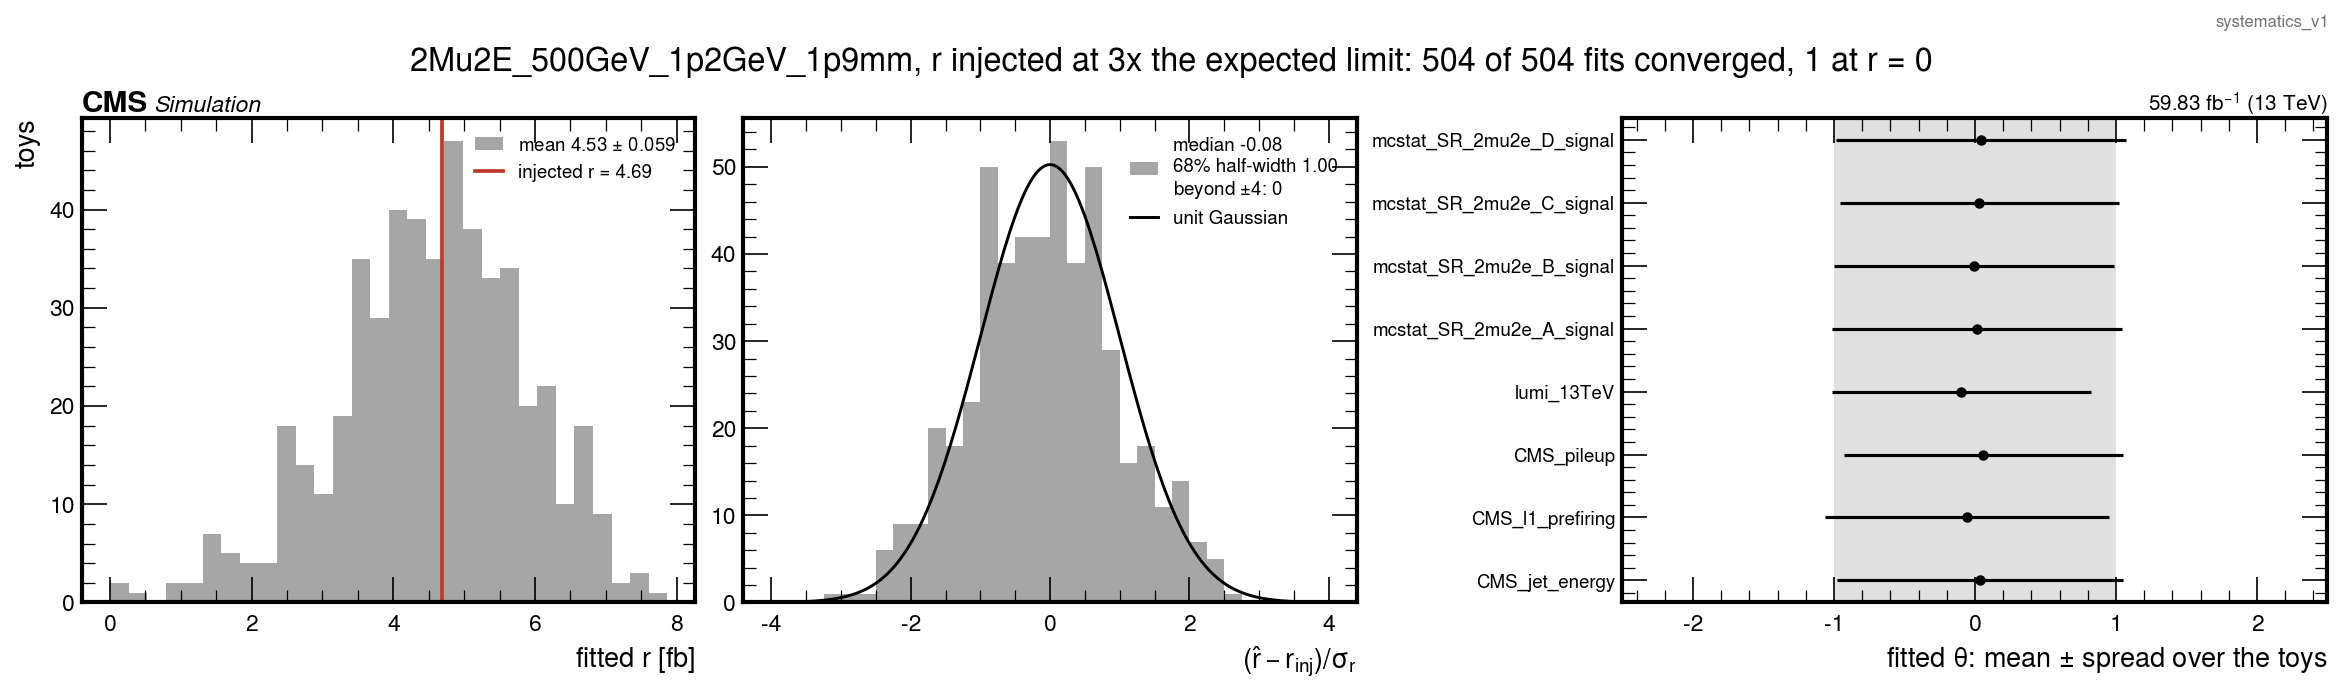

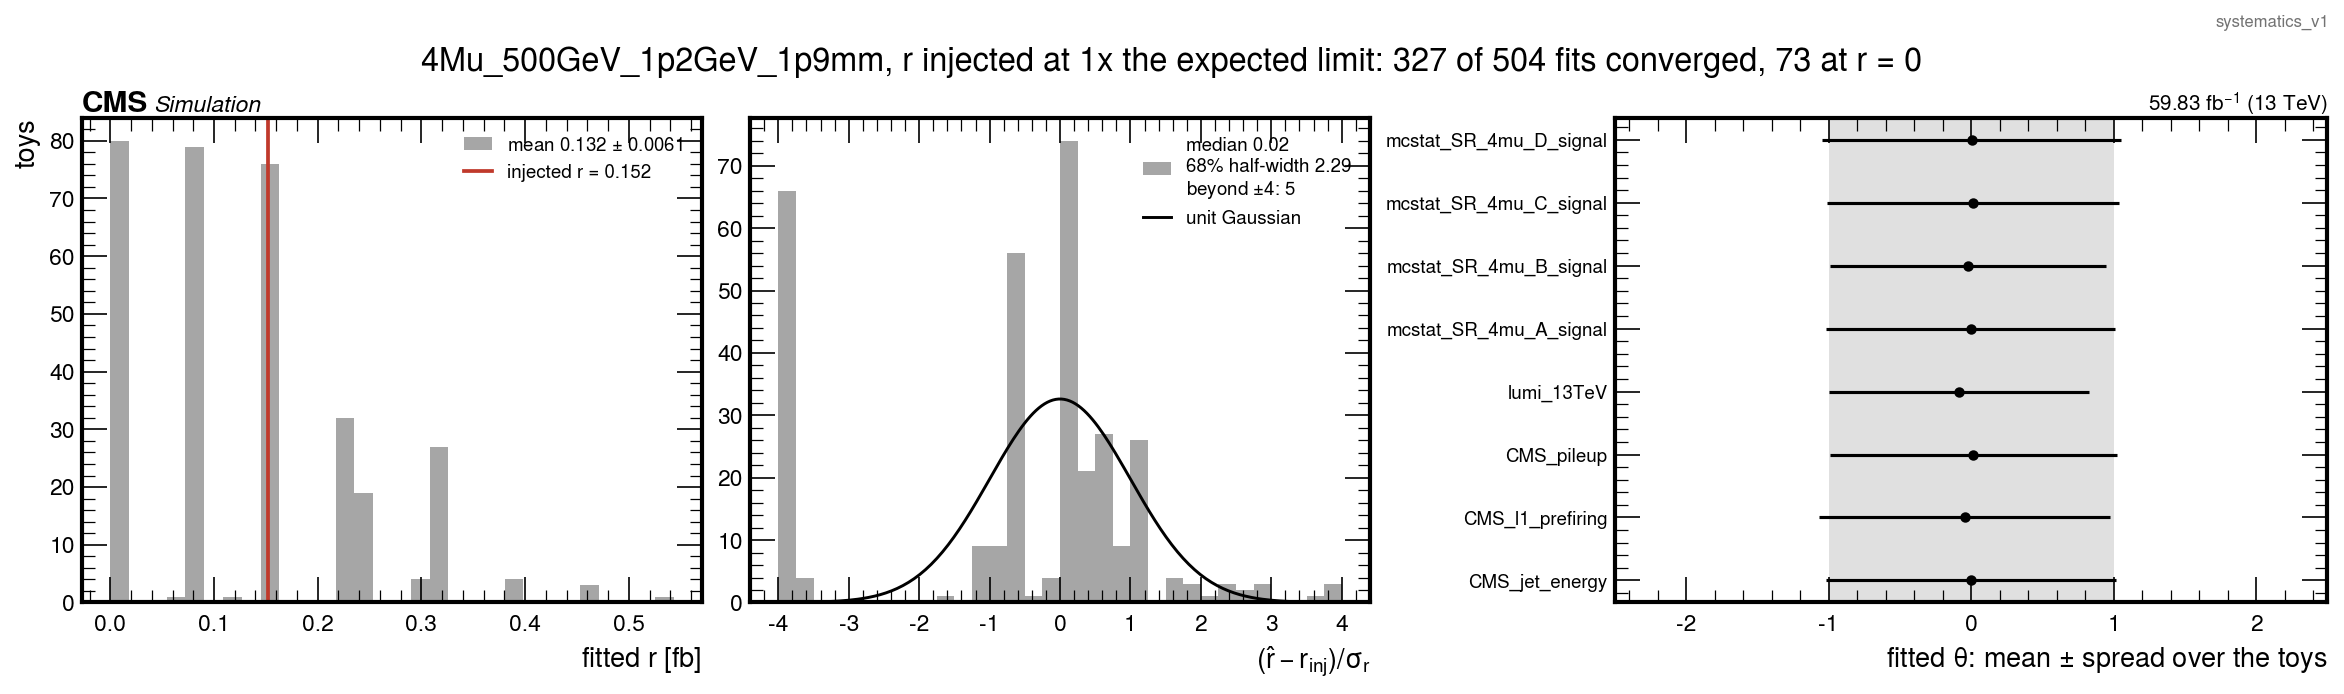

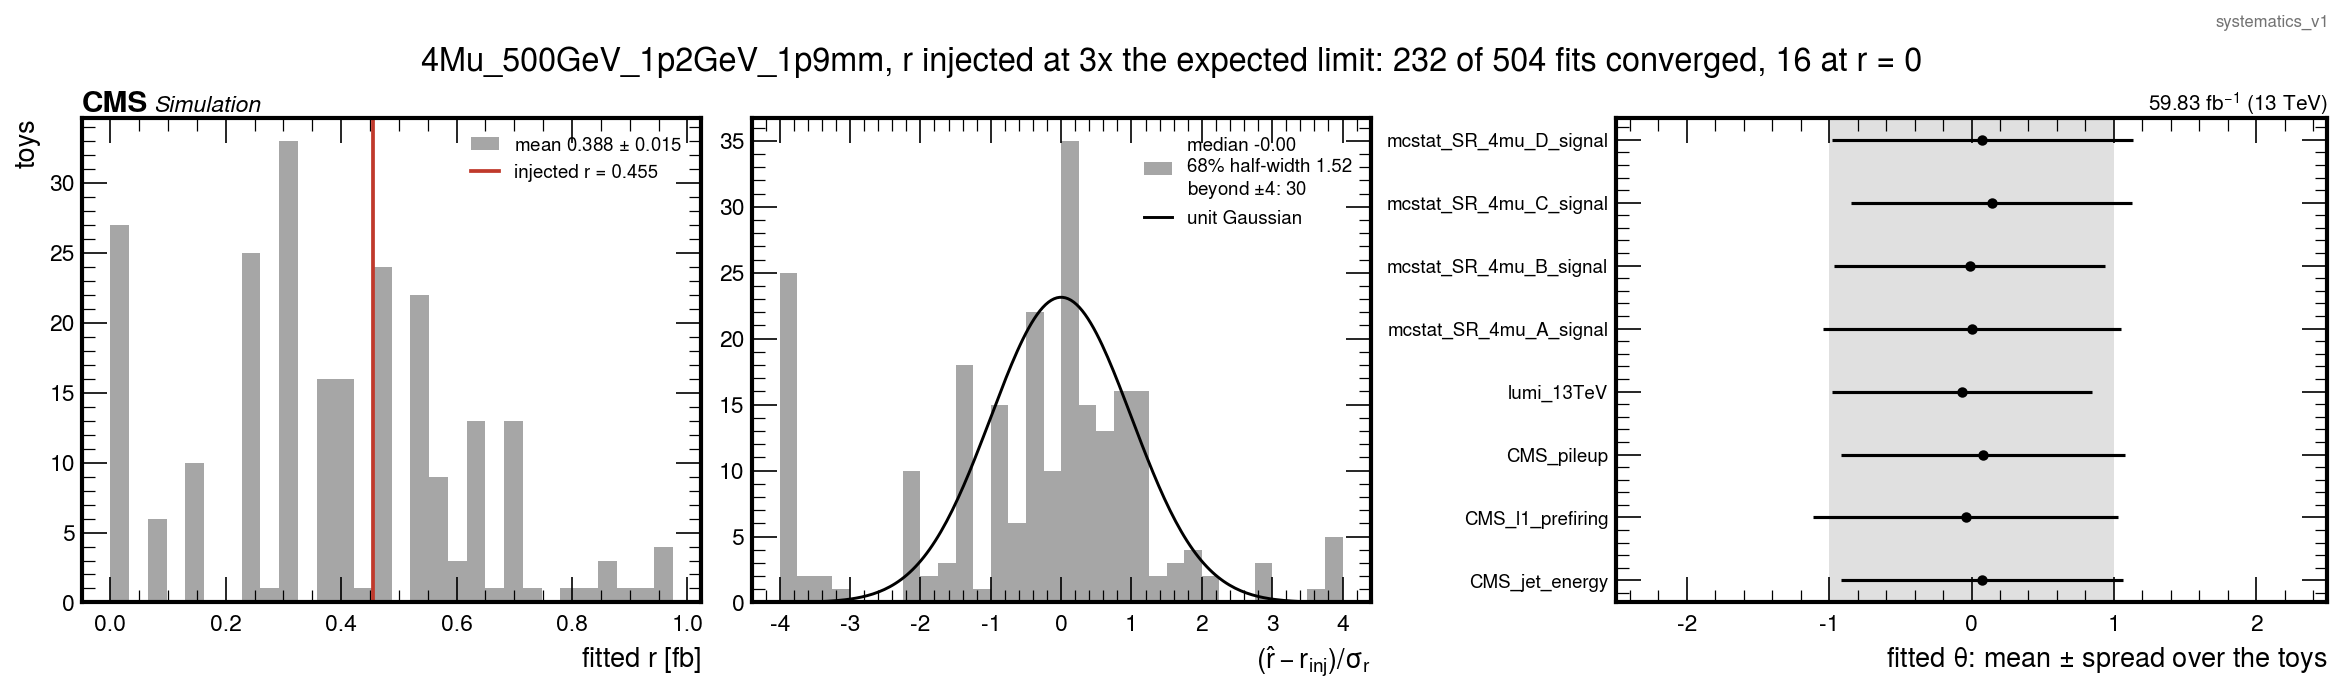

In [2]:
if COMBINE is None:
    raise RuntimeError("Combine is not available here: put `combine` on the PATH or set COMBINE_CMSSW_BASE.")
CARDS = WORK / "cards"
sysstudy.download(f"{LIMITS_DIR}/cards_with", CARDS)   # the cards with corrections and systematics

for channel, point in POINTS.items():
    card = CARDS / f"datacard_shape_{channel}_{point}.txt"
    for factor in (1, 3):
        outdir = WORK / f"toys_{point}_x{factor}"
        sysstudy.run_script("run_combine_toys.py", card, "--outdir", outdir,
                            "--expect-signal", f"{factor * EXPECTED[point]:.6g}", "--toys", NTOYS, "-j", "8",
                            combine=COMBINE, log=WORK / f"toys_{point}_x{factor}.log")
        toys = json.loads((outdir / "toys.json").read_text())
        show(pt.bias_plot(toys, FIGURES, CAMPAIGN, f"injection_{point}_x{factor}",
                          title=f"{point}, r injected at {factor}x the expected limit"))

**Interpretation (run of 2026-11-14: `systematics_v1`, four systematics).**

*2Mu2E.* At three times the expected limit the fit recovers the injected signal with a small
low bias and the right uncertainty: the mean fitted $r$ is 4.53 ± 0.06 against 4.69 injected
(3% low, 0.08 of the uncertainty of $r$), the median pull is −0.08 and its 68% half-width 1.00,
with no pull beyond ±4. At the expected limit, 52 of the 504 toys (10%) stop at the $r = 0$
boundary and make the left tail; the median pull is −0.13 and the half-width 1.03. All 1008 fits
converge, and every nuisance comes back as $0 \pm 1$.

*4Mu.* The test does not validate the 4mu fit at this working point.
* Only 327 of 504 fits converge at the expected limit, and 232 of 504 at three times it. The
  failures come from toys with empty control regions: region C expects 0.003 background events,
  so it is empty in almost every toy, and D (0.75 events) in about half. In a separate check with
  80 saved toys at three times the expected limit, 34 of the 35 toys with both C and D empty
  failed, against 19 of the 41 with only C empty.
* The converged fits return $r$ 13 to 15% low, and their pull is not Gaussian (68% half-width
  1.5 to 2.3): with 2 to 6 signal events and no background, the fitted $r$ takes discrete values,
  one step of about 0.08 fb per event, which asymptotic uncertainties do not describe.

**For the analysis:** the 2mu2e fit with the systematics is unbiased to within a few percent and
its uncertainty is right, so its limits can be trusted as far as the fit goes (the caveat on the
simulated background in 03_limits stands). The 4mu ABCD prediction is undefined whenever C and D
are empty, which happens in most toys here and is the limitation already seen in the control
regions in data at this working point. The 4mu expected limits, computed on the Asimov dataset,
do not depend on it, but the choice of the 4mu working point or method, which the group is
discussing, should be made with this test rerun on it.

## 6. Likelihood scans

The first panel of each point scans $r$: grey without signal, blue with the signal at the
expected limit; solid with every nuisance, dashed with statistics only. The two line styles
lie on top of each other where the systematics do not matter. The other panels scan each
systematic with $r$ floating, against $\theta^2$, what its unit Gaussian constraint gives by
itself: a scan on top of $\theta^2$ means the data add nothing to the constraint, as for any
nuisance that acts on the signal alone. The dotted lines mark the 68% and 95% CL crossings
of one parameter.

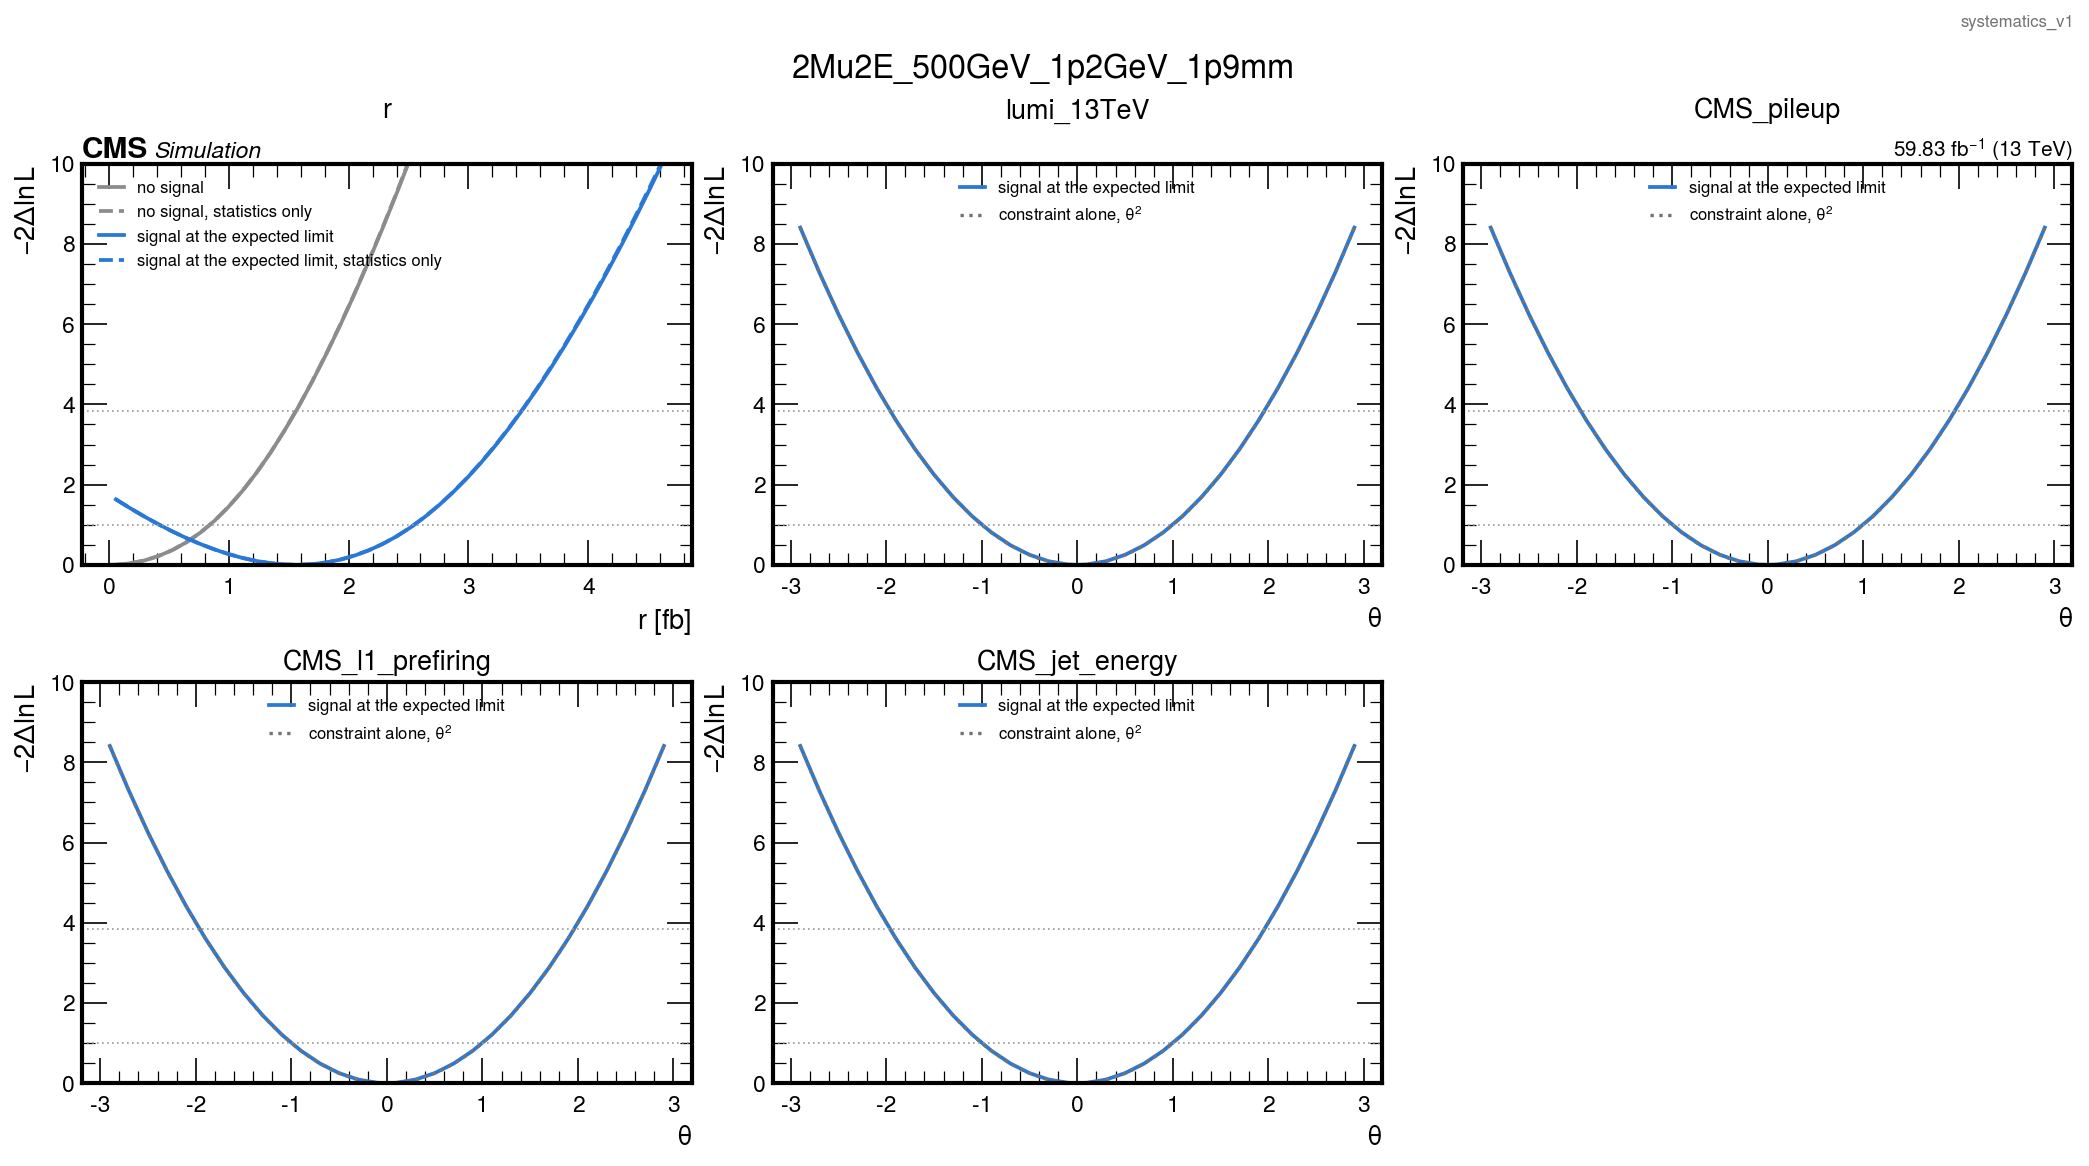

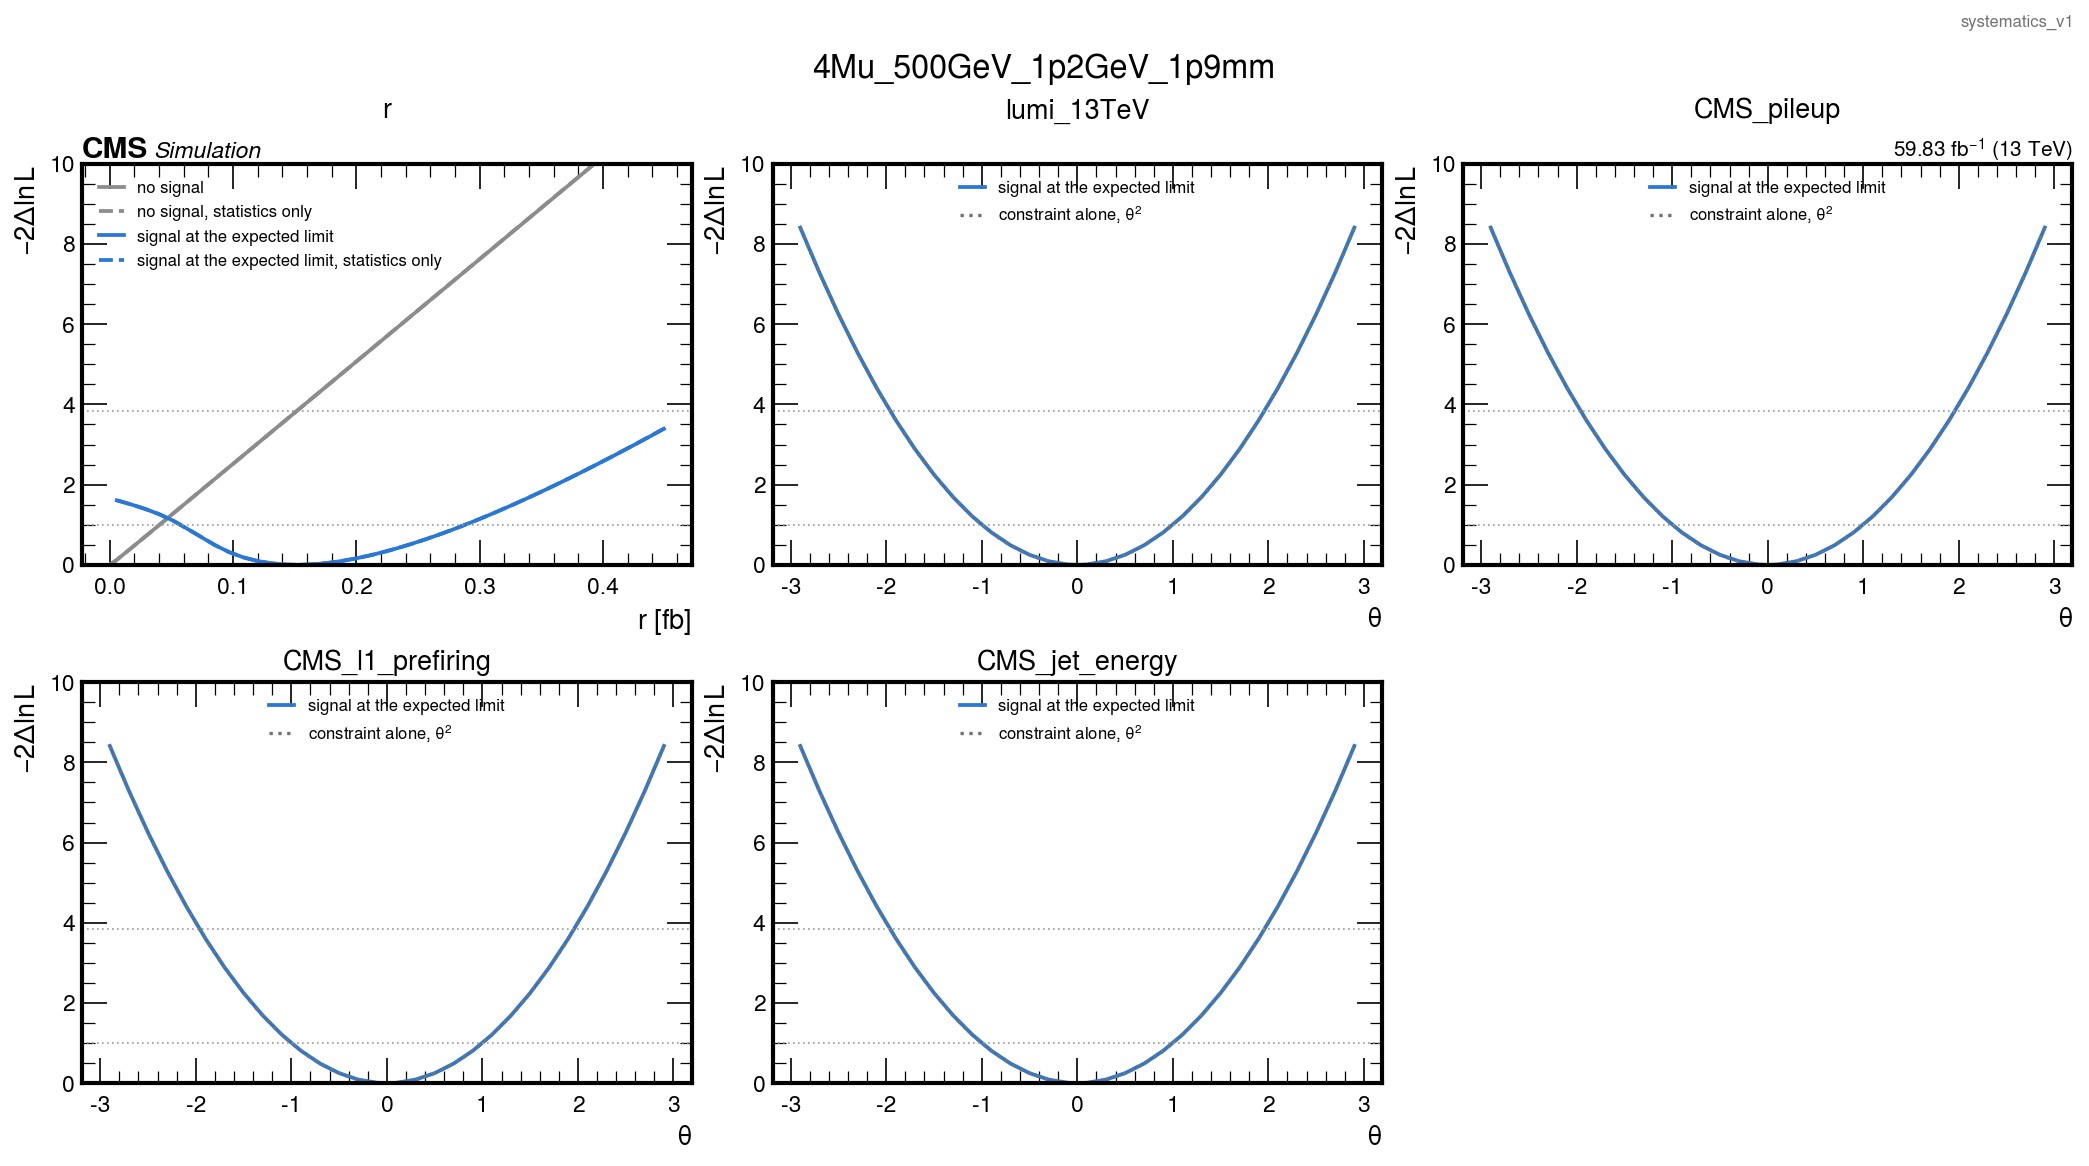

In [3]:
STYLES = {"no signal": dict(color=study.GRAY, ls="-"),
          "no signal, statistics only": dict(color=study.GRAY, ls="--"),
          "signal at the expected limit": dict(color=study.BLUE, ls="-"),
          "signal at the expected limit, statistics only": dict(color=study.BLUE, ls="--")}
for channel, point in POINTS.items():
    card = CARDS / f"datacard_shape_{channel}_{point}.txt"
    outdir = WORK / f"scans_{point}"
    signal = EXPECTED[point]

    def scan(poi, value_range, points, injected, frozen="", name=""):
        """One scan of this point's card, run_combine_scan.py output"""
        name = name or poi
        sysstudy.run_script("run_combine_scan.py", card, "--outdir", outdir, "--poi", poi, f"--range={value_range}",
                            "--points", points, "--expect-signal", f"{injected:.6g}", "--name", name,
                            *(["--freeze", frozen] if frozen else []),
                            combine=COMBINE, log=WORK / f"scan_{point}_{name}.log")
        return json.loads((outdir / f"scan_{name}.json").read_text())

    r_scans = {}
    for label in STYLES:
        r_scans[label] = scan("r", f"0,{3 * signal:.4g}", 40, 0 if label.startswith("no signal") else signal,
                              "allConstrainedNuisances" if label.endswith("statistics only") else "",
                              "r_" + label.replace(",", "").replace(" ", "_"))
    panels = [("r", r_scans, False)]
    panels += [(nuisance, {"signal at the expected limit": scan(nuisance, "-3,3", 30, signal)}, True)
               for nuisance in REGISTRY]
    show(pt.scan_plot(panels, FIGURES, CAMPAIGN, f"scans_{point}", title=point, styles=STYLES))

**Interpretation.** For both points the scans of $r$ with every nuisance and with statistics only
lie on top of each other: the systematics do not widen the likelihood.
* 2Mu2E: with the signal at the expected limit the scan is close to a parabola around 1.56 fb,
  slightly asymmetric (about $-1.1/+1.0$ at $-2\Delta\ln L = 1$), and the background-only scan
  crosses 3.84 near the expected limit.
* 4Mu: the background-only scan is a straight line, what a Poisson likelihood without background
  gives ($-2\Delta\ln L \approx 2sr$ for a signal yield $sr$ and nothing observed), and it crosses
  3.84 at the expected limit of 0.15 fb. With the signal injected the curve is strongly
  asymmetric.
* The scan of every systematic lies on $\theta^2$: the data add nothing to the constraints, as for
  any nuisance that acts on the signal alone.

**For the analysis:** the 2Mu2E likelihood is close to Gaussian near its minimum and the 4Mu one is
a counting likelihood without background; the systematics leave both unchanged. A nuisance scan
that departs from $\theta^2$ (narrower: constrained by the data; off-centre: pulled) is what to
look for once nuisances on the background are added.

## 7. Correlations

The parameters are ordered as $r$, the systematics, the statistical uncertainties of the
simulated signal (`mcstat`), and the free background parameters of regions B, C and D, bin
by bin; coefficients of at least 0.1 in size are printed. The fit status is printed below
each matrix: anything but 0 means that MINUIT could not determine the uncertainty of every
parameter. In the tests that came from background bins of region C without any simulated
events, whose parameters sit at zero and correlate with nothing.

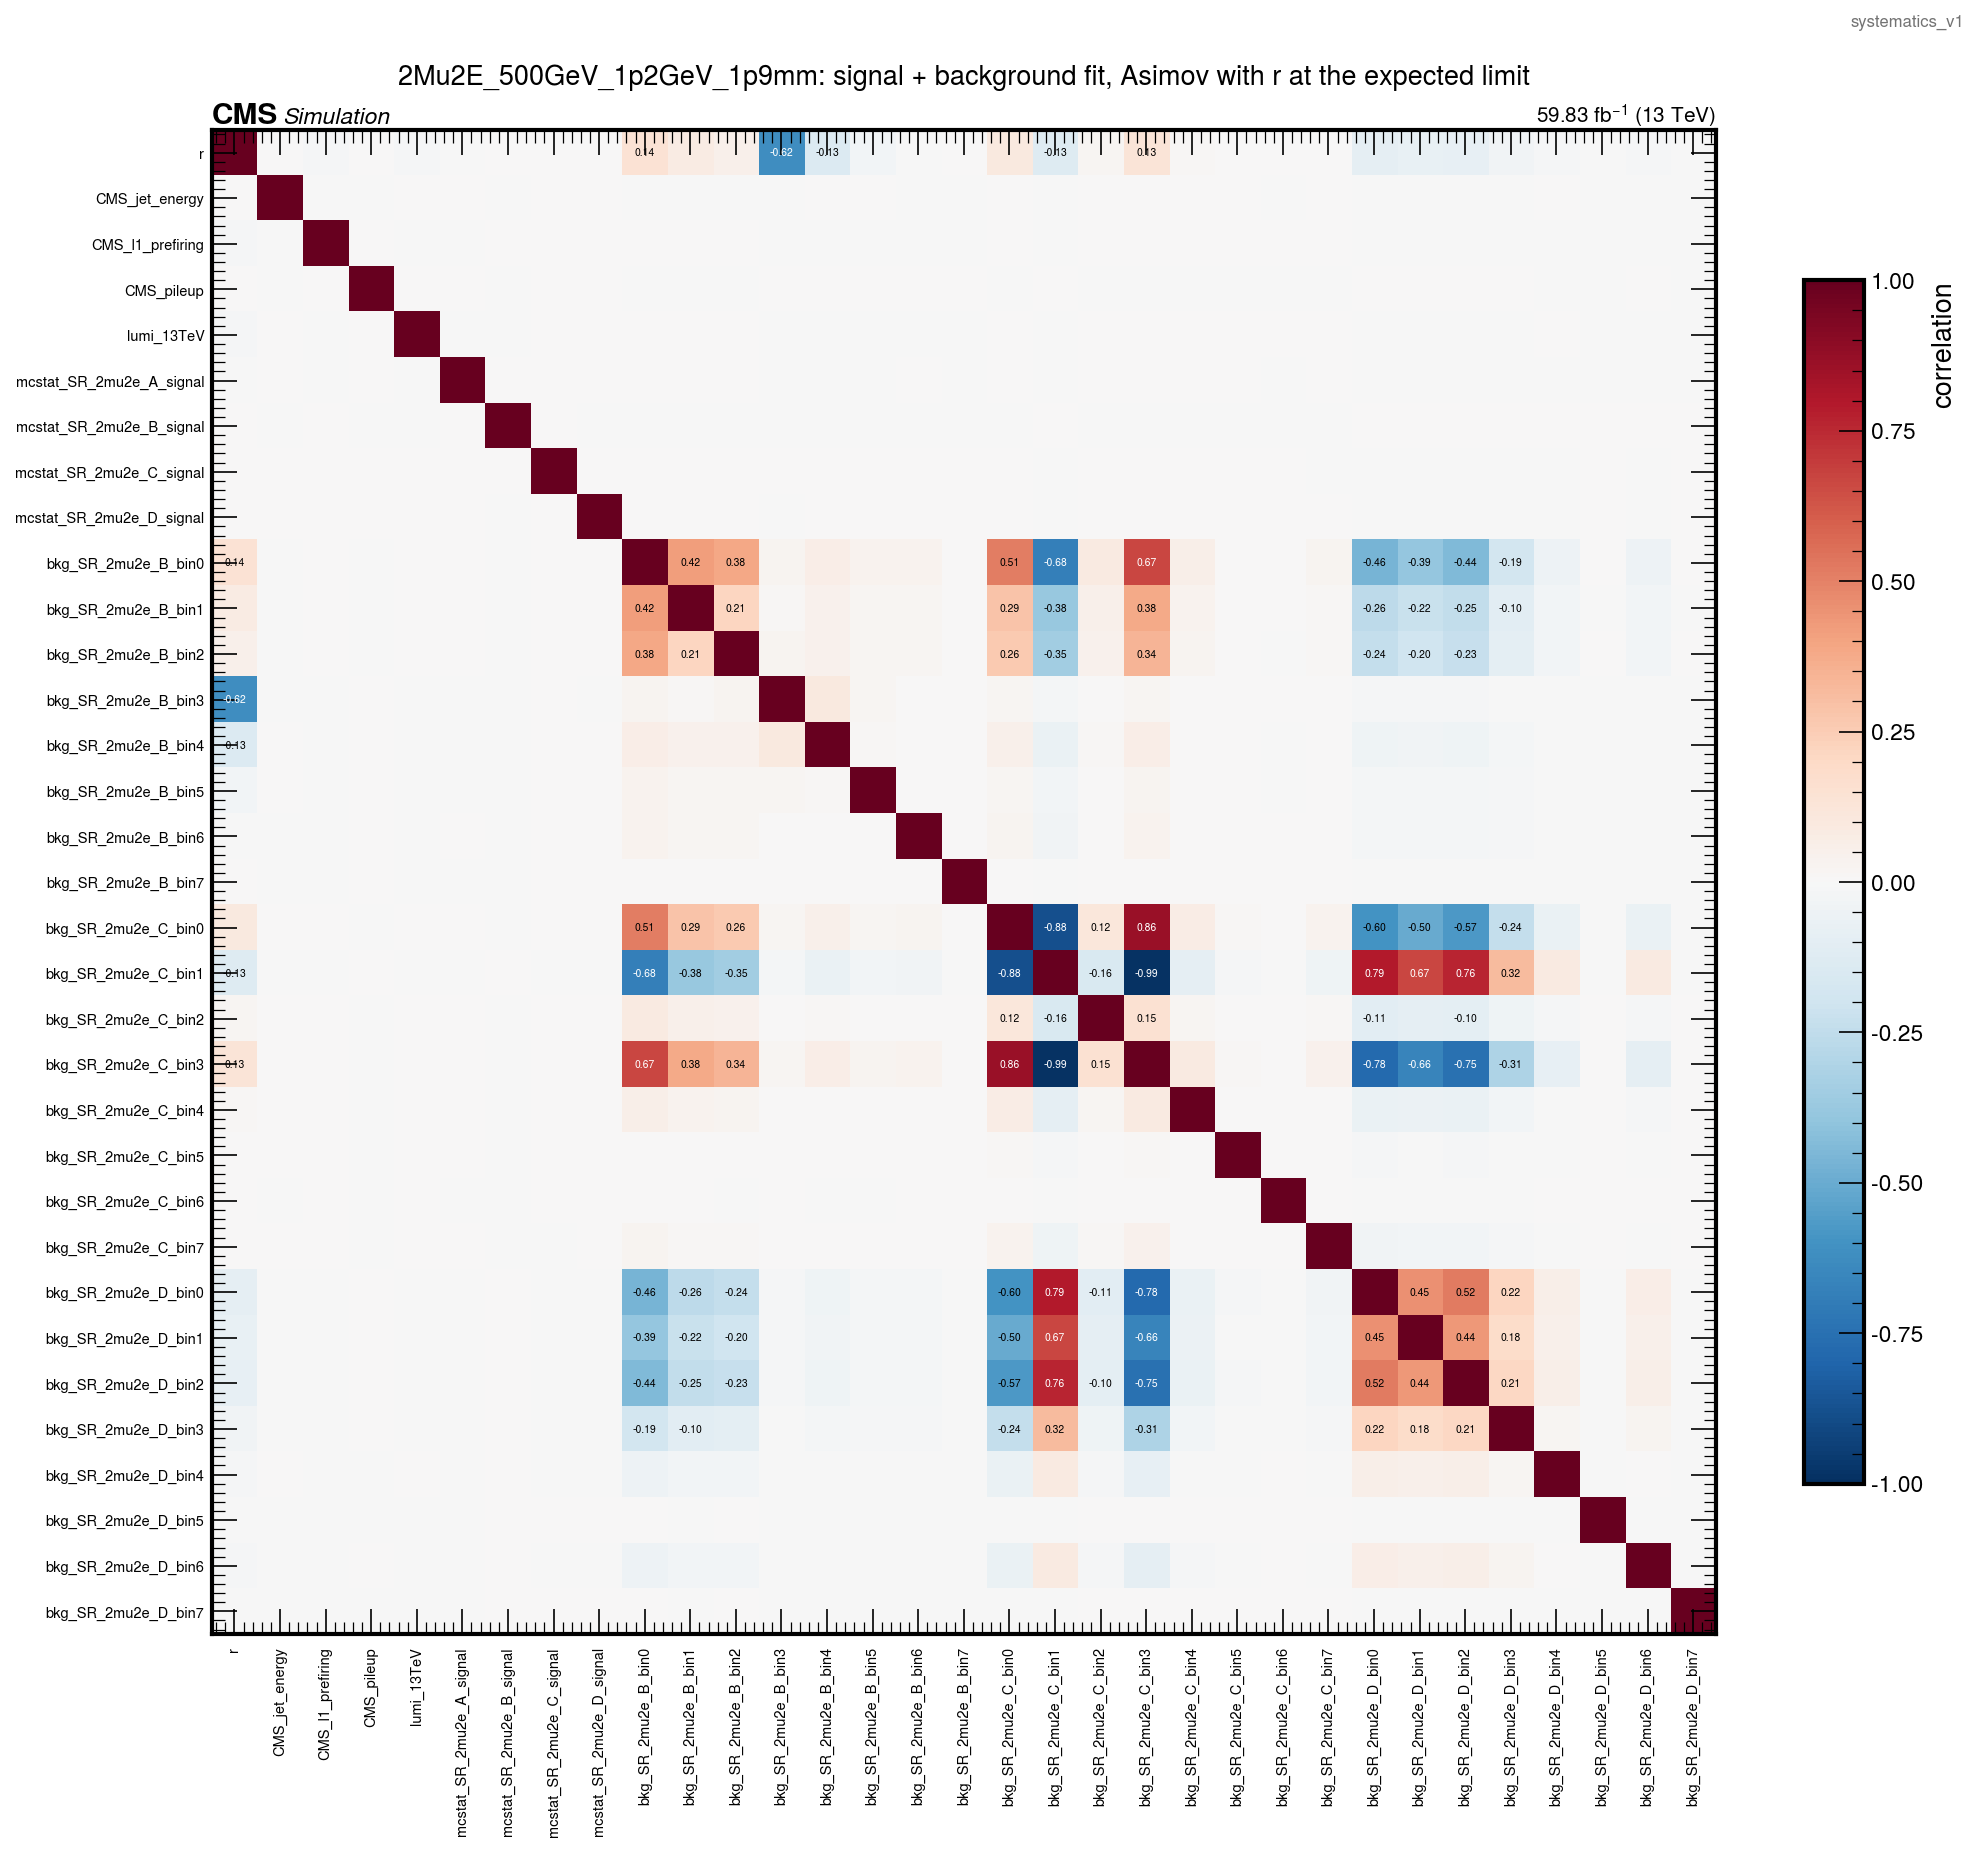

2Mu2E_500GeV_1p2GeV_1p9mm: fit status 1


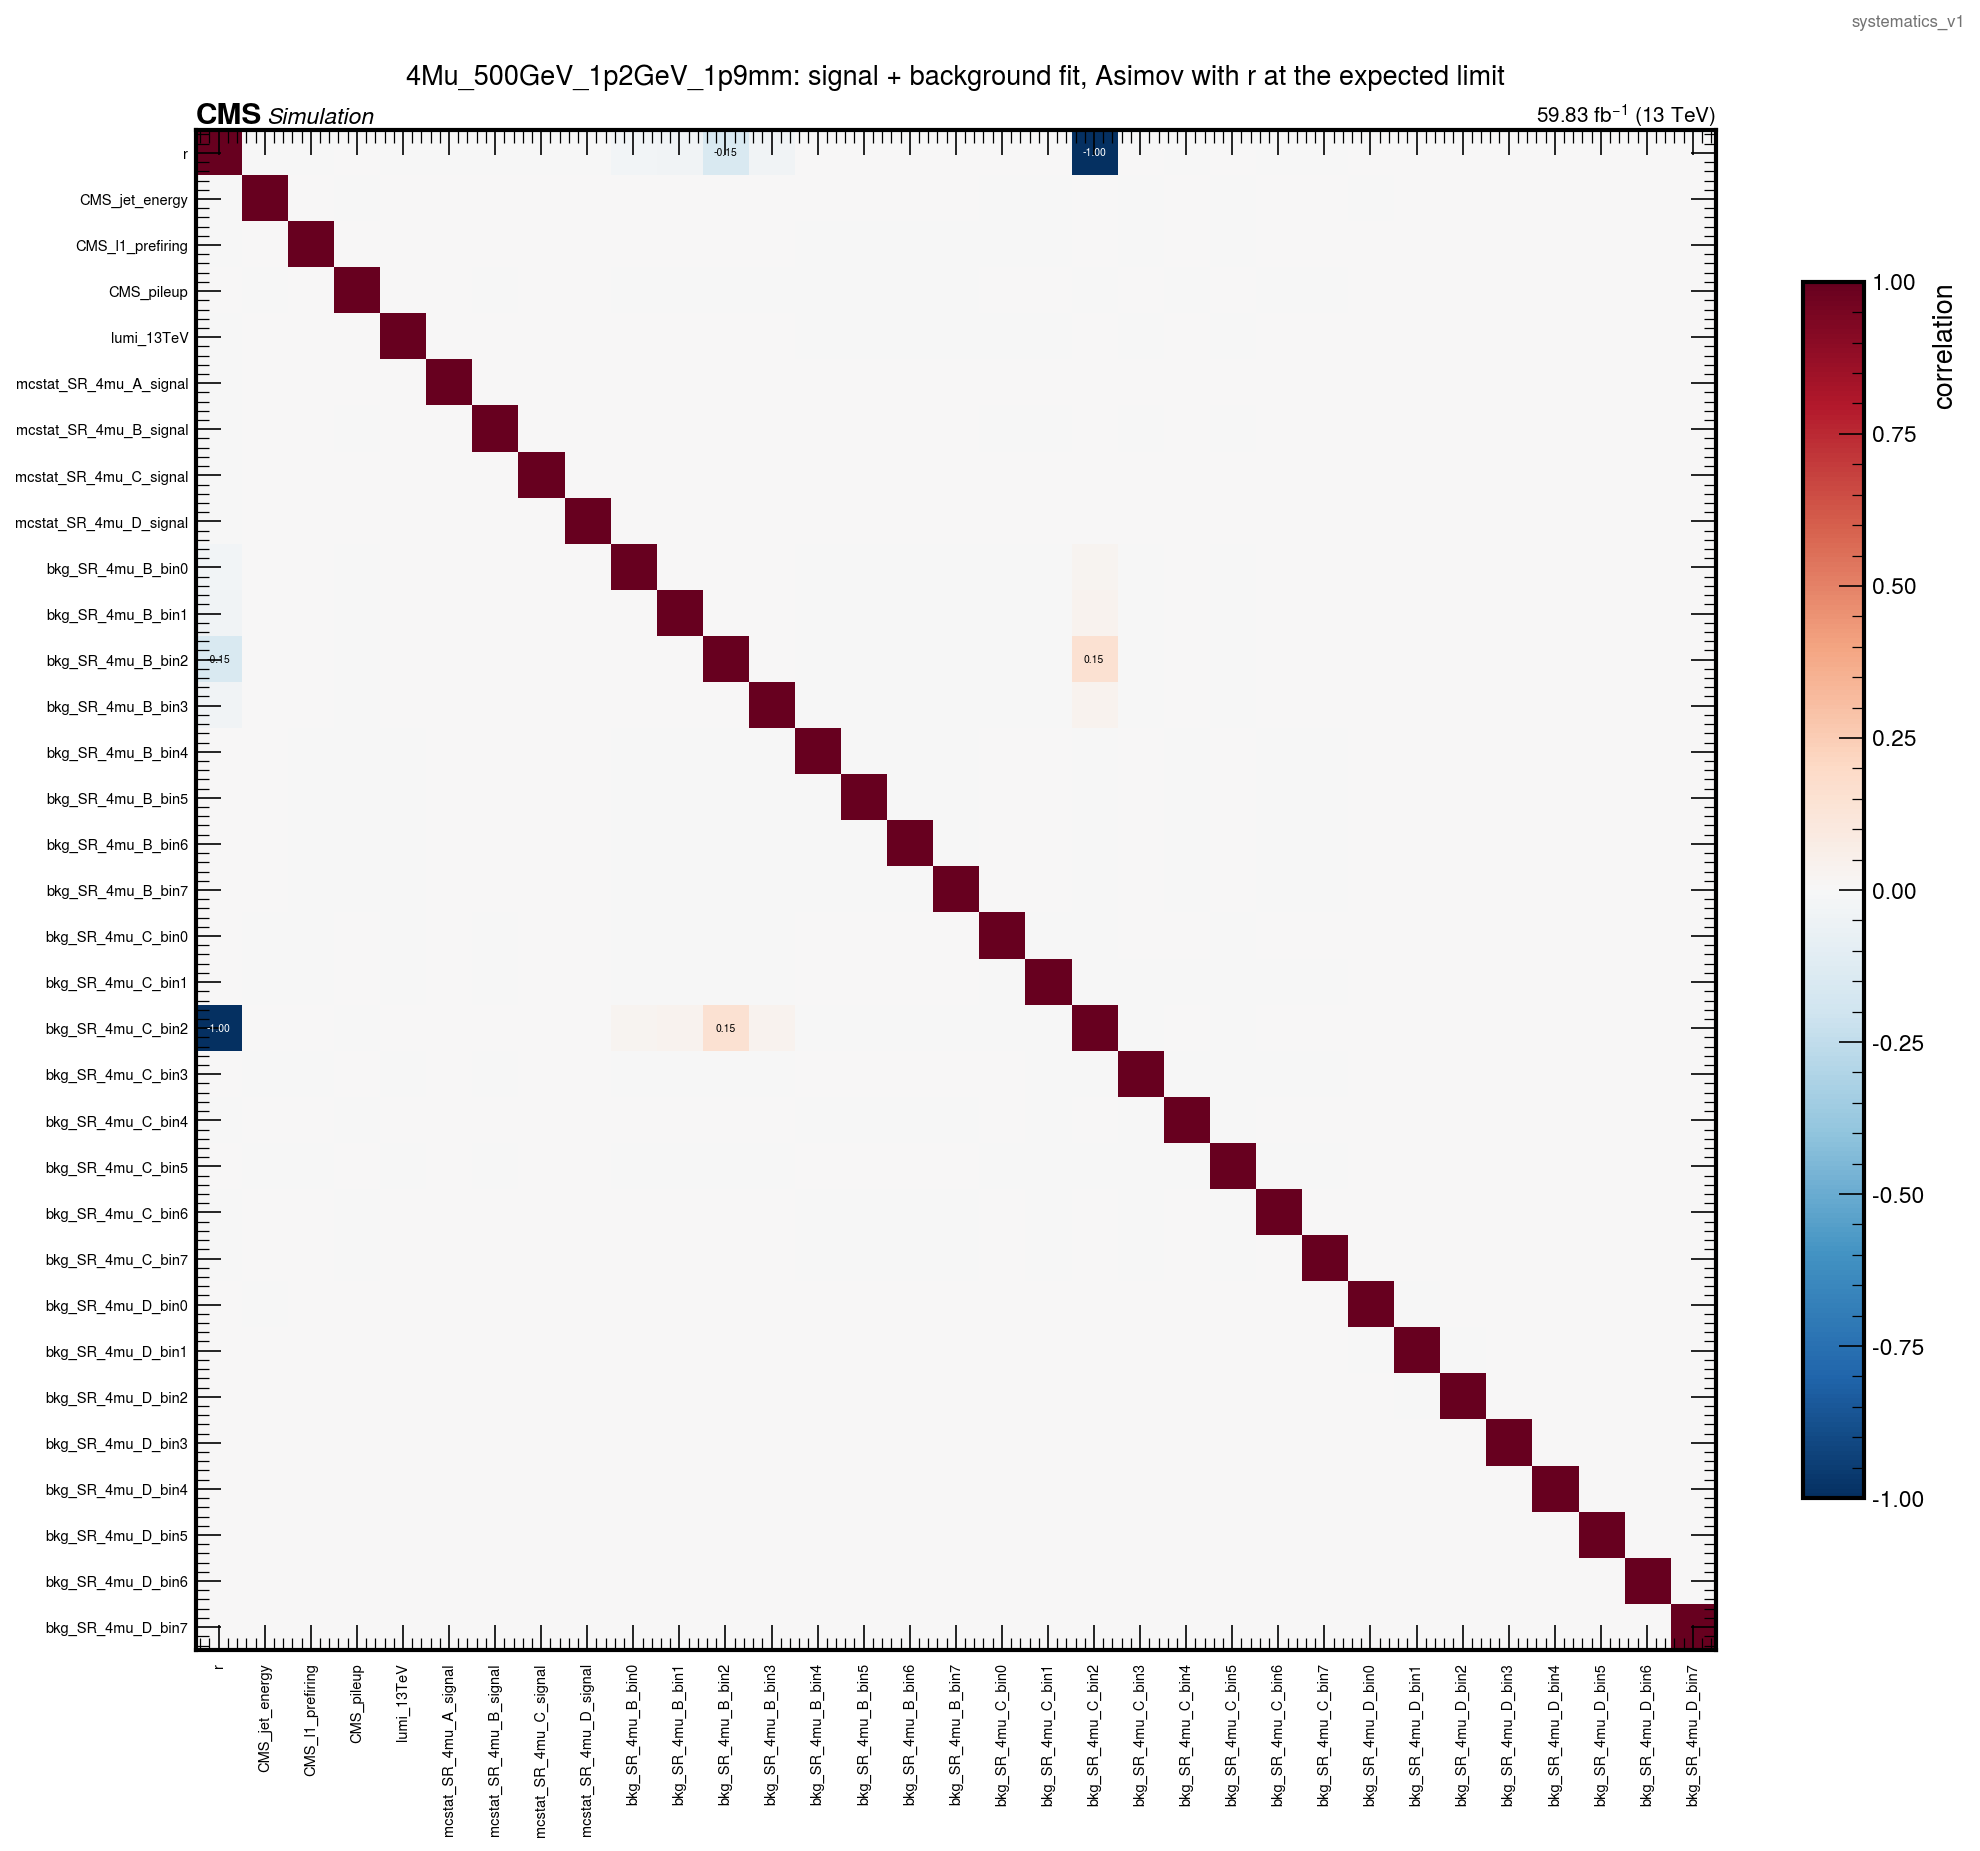

4Mu_500GeV_1p2GeV_1p9mm: fit status 1


In [4]:
def order(name):
    """r first, then the systematics, the signal MC statistics and the background parameters"""
    return (name != "r", name not in REGISTRY, name.startswith("bkg_"), name)


for channel, point in POINTS.items():
    outdir = WORK / f"fit_{point}"
    sysstudy.run_script("run_combine_pulls.py", CARDS / f"datacard_shape_{channel}_{point}.txt",
                        "--outdir", outdir, "--expect-signal", f"{EXPECTED[point]:.6g}",
                        combine=COMBINE, log=WORK / f"fit_{point}.log")
    fit = json.loads((outdir / "pulls.json").read_text())
    correlation = fit["correlation"]["fit_s"]
    index = sorted(range(len(correlation["names"])), key=lambda i: order(correlation["names"][i]))
    show(pt.correlation_plot([correlation["names"][i] for i in index],
                             [[correlation["matrix"][i][j] for j in index] for i in index],
                             FIGURES, CAMPAIGN, f"correlations_{point}",
                             title=f"{point}: signal + background fit, Asimov with r at the expected limit"))
    print(f"{point}: fit status {fit['status'].get('fit_s')}")

**Interpretation.** The systematics are uncorrelated with everything, $r$ included, at the 0.1
level printed: on the Asimov dataset they keep their pre-fit values and trade off against no
other parameter. The structure is in $r$ and the background parameters.
* 2Mu2E: $r$ is anti-correlated (−0.62) with the background of region B in the 400 to 600 GeV
  bin, where the signal of this 500 GeV point leaks into B. The background parameters of C and D
  are strongly correlated with each other, since they enter region A only through the transfer
  factor, the ratio of their sums.
* 4Mu: $r$ is fully anti-correlated (−1.00) with one background parameter of region C (300 to
  400 GeV). Region C holds almost no background (0.003 events), so its content in the Asimov
  dataset is mostly signal and the fit cannot separate the two there; with fit status 1, the −1
  marks a direction the fit cannot resolve rather than a precise correlation.

Both fits have status 1: MINUIT could not determine the uncertainty of every parameter, which in
the tests came from background bins without any simulated events in region C.

**For the analysis:** signal in the control regions is what couples $r$ to the background
estimate. In 2mu2e it is small and the coupling partial; in 4mu region C has no background to
measure, the empty-control-region problem of the signal-injection test seen from the fit.

Everything but the copies of the cards goes to EOS, and the local working directory is removed.

In [5]:
for copies in WORK.glob("cards*"):
    shutil.rmtree(copies)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/systematics_v1_limits/fit_checks
